# 2. Модельдерді әзірлеу, салыстыру және бағалау

**Міндет:** суреттегі иттің тұқымын 120 класс бойынша анықтау (көпкласты кескін жіктеу).

**Негізгі тәсіл — transfer learning** (GeeksforGeeks мақаласындағыдай):
1. ImageNet-те (1,2 млн сурет, 1000 класс) алдын ала үйретілген конволюциялық желіні аламыз;
2. оның салмақтарын **мұздатамыз** (`trainable = False`): ол суретті белгілер векторына айналдыратын «көз» рөлін атқарады;
3. оның үстіне жаңа классификатор (**head**) қосып, тек соны біздің 120 тұқымға оқытамыз.

**Неге белгілерді алдын ала сақтадық?** Мұздатылған желінің шығысы әр эпохада бірдей. Сондықтан әр суреттің белгілер векторын бір рет есептеп,
дискке сақтадық (`scripts/02_extract_features.py`). Сонда классификаторды оқыту GPU-сыз да бірнеше секунд алады. Бұл мақаладағы тәсілмен математикалық тұрғыдан бірдей.
Мақаладағыдай **кеңейту (augmentation)** ретінде көлденең айналдырылған суреттердің белгілері де қосылды.

**Салыстырылған модельдер**
| Топ | Модельдер |
|---|---|
| Бастапқы (baseline) | ең жиі класс (кездейсоқ деңгей); нөлден оқытылған шағын CNN |
| Transfer learning | 3 негізгі желі (MobileNetV2, EfficientNetB0, InceptionResNetV2) × 3 классификатор (мақаладағы MLP басы, сызықтық бас, LogisticRegression) |
| Оқытусыз (zero-shot) | ImageNet-тің өз 1000 класты басы, 120 тұқымға сәйкес бағандары ғана |

**Ереже:** гиперпараметрлер мен соңғы модель тек **val** бойынша таңдалады, ал **test** тек соңғы бағалауға қолданылады.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from IPython.display import Image, display

from src import plot_style
from src.config import FEATURES_DIR, FIG_DIR, HISTORY_DIR, METRICS_DIR, SEED
from src.data_utils import load_json
from src.heads import article_head, linear_head
from src.metrics import classification_metrics

%matplotlib inline
plot_style.apply()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

## 1. Белгілерді шығару: қанша уақыт кетті?

Әр желі үшін: параметр саны (тек «дене», ImageNet басынсыз), есептеу құралы және жылдамдық.
InceptionResNetV2 өте ауыр болғандықтан, оның белгілері Intel GPU-да **OpenVINO** арқылы шығарылды (FP32 дәлдікпен, TensorFlow нәтижесімен айырмасы ~2·10⁻⁶).
Сайттың өзі TensorFlow-да жұмыс істейді.

In [2]:
rows = []
for bb in ["mobilenet_v2", "efficientnet_b0", "inception_resnet_v2"]:
    t = load_json(FEATURES_DIR / bb / "timing.json")
    rows.append({"модель": bb, "параметр, млн": round(t["backbone_params"] / 1e6, 1), "құрал": t.get("engine"),
                 "train, сурет/с": t.get("train", {}).get("images_per_sec"),
                 "вектор өлшемі": np.load(FEATURES_DIR / bb / "val.npy", mmap_mode="r").shape[1]})
pd.DataFrame(rows)

,модель,"параметр, млн",құрал,"train, сурет/с",вектор өлшемі
0,mobilenet_v2,2.3,NaN,63.67,1280
1,efficientnet_b0,4.0,NaN,39.70,1280
2,inception_resnet_v2,54.3,openvino-gpu-fp32,8.26,1536


## 2. Мақаланы қайталау: InceptionResNetV2 + мақаладағы MLP басы

Мақаладағы бас: `BatchNorm → Dense(512, relu) → Dense(256, relu) → Dropout(0.5) → Dense(128, relu) → Dense(120, softmax)`,
`Adam` (lr = 0.001), `batch_size = 32`, 25 эпохаға дейін, `EarlyStopping(patience=10, min_delta=0.001, restore_best_weights=True)`.

Төменде дәл осы модельді сақталған белгілерде **осы ноутбуктың ішінде** қайта оқытамыз (CPU-да бірнеше минут).
Мақаладан айырмасы: кіріс өлшемі 331 емес, модельдің өз өлшемі 299×299, және пиксельдер 255-ке бөлінбей, модельдің өз `preprocess_input` функциясымен [-1, 1] ауқымына келтірілді.

In [3]:
def load(bb, split):
    x = np.load(FEATURES_DIR / bb / f"{split}.npy").astype(np.float32)
    y = np.load(FEATURES_DIR / bb / f"{split}_y.npy").astype(np.int64)
    return x, y

bb = "inception_resnet_v2"
x_tr, y_tr = load(bb, "train")
x_fl = np.load(FEATURES_DIR / bb / "train_flip.npy").astype(np.float32)
x_tr, y_tr = np.concatenate([x_tr, x_fl]), np.concatenate([y_tr, y_tr])   # айналдыру = кеңейту
x_val, y_val = load(bb, "val")
print("train:", x_tr.shape, " val:", x_val.shape)

keras.utils.set_random_seed(SEED)
model = article_head(x_tr.shape[1])
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

train: (20140, 1536)  val: (1800, 1536)


Model: "article_head"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ features (InputLayer)           │ (None, 1536)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1536)           │         6,144 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       786,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ breed (Dense)                   │ (None, 120)            │        15,480 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 972,792 (3.71 MB)

 Trainable params: 969,720 (3.70 MB)

 Non-trainable params: 3,072 (12.00 KB)

Epoch 1/25


630/630 - 8s - 13ms/step - accuracy: 0.8137 - loss: 0.8220 - val_accuracy: 0.8983 - val_loss: 0.4628


Epoch 2/25


630/630 - 7s - 10ms/step - accuracy: 0.8851 - loss: 0.4535 - val_accuracy: 0.9106 - val_loss: 0.4307


Epoch 3/25


630/630 - 6s - 9ms/step - accuracy: 0.8973 - loss: 0.3870 - val_accuracy: 0.9072 - val_loss: 0.4552


... (14 outputs left out)

Epoch 11/25


630/630 - 6s - 10ms/step - accuracy: 0.9478 - loss: 0.1625 - val_accuracy: 0.9144 - val_loss: 0.5970


Epoch 12/25


630/630 - 6s - 9ms/step - accuracy: 0.9489 - loss: 0.1670 - val_accuracy: 0.9083 - val_loss: 0.6026


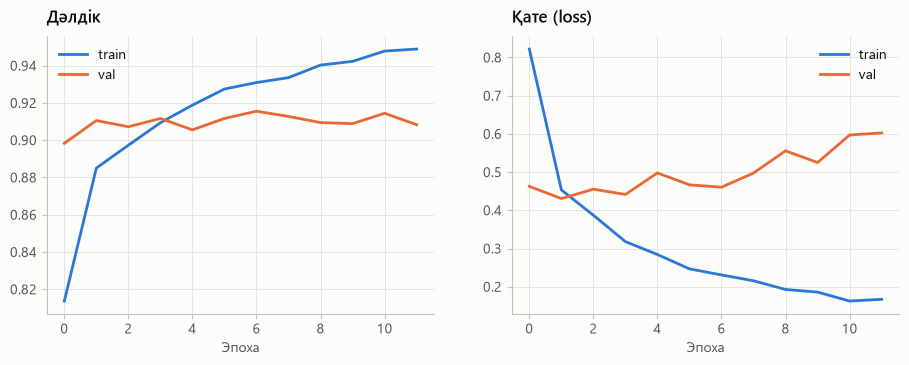

Val дәлдігі: 0.9106   (мақалада: 0.9023, Kaggle деректері)


In [4]:
early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, min_delta=0.001, restore_best_weights=True)
hist = model.fit(x_tr, y_tr, validation_data=(x_val, y_val), epochs=25, batch_size=32, callbacks=[early], verbose=2)

h = hist.history
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, key, title in [(axes[0], "accuracy", "Дәлдік"), (axes[1], "loss", "Қате (loss)")]:
    ax.plot(h[key], color=plot_style.C["blue"], label="train")
    ax.plot(h["val_" + key], color=plot_style.C["orange"], label="val")
    ax.set_xlabel("Эпоха"); ax.set_title(title); ax.legend()
plt.show()
val_acc = model.evaluate(x_val, y_val, verbose=0)[1]
print(f"Val дәлдігі: {val_acc:.4f}   (мақалада: 0.9023, Kaggle деректері)")

**Нәтиже.** Скрипттегі дәл осындай оқытуда (`scripts/04_train_heads.py`) мақаланың басы валидацияда **91,1%**, test-те **90,8%** көрсетті
(мақалада валидация дәлдігі 90,2%). Яғни мақаланың нәтижесі расталды. Бірақ оқу қисықтарынан көрінетіні: train дәлдігі val-дан жоғары кетеді,
ал val loss алғашқы эпохалардан кейін өсе бастайды. Яғни бұл бас **шамадан тыс үйренеді (overfitting)**: онда ~1 млн параметр бар, ал бір тұқымға небәрі ~85 сурет келеді.

## 3. Барлық модельді салыстыру

Барлық модель скрипттерде оқытылып (`scripts/03_*`, `scripts/04_*`), бірдей test жиынында бағаланды (`scripts/06_evaluate.py`).
`+TTA` — болжамды суреттің өзі мен оның айналдырылған нұсқасы бойынша орташалау (test-time augmentation).

In [5]:
comp = pd.read_csv(METRICS_DIR / "comparison.csv")
cols = ["title", "family", "test_accuracy", "test_top5_accuracy", "test_macro_f1", "test_log_loss", "test_ece",
        "val_accuracy", "params", "latency_ms"]
comp.sort_values("test_accuracy", ascending=False)[cols].round(4)

,title,family,test_accuracy,test_top5_accuracy,test_macro_f1,test_log_loss,test_ece,val_accuracy,params,latency_ms
17,"InceptionResNetV2: ImageNet басы, оқытусыз",zero-shot,0.9259,0.9972,0.9211,0.2392,0.0196,0.9206,54336736,204.3
2,InceptionResNetV2 + сызықтық бас,transfer,0.9249,0.9943,0.9219,0.2491,0.0124,0.9217,54521176,204.3
3,InceptionResNetV2 + LogisticRegression,transfer,0.9161,0.9923,0.9125,0.2959,0.0296,0.9144,54336736,204.3
4,InceptionResNetV2 + мақаладағы MLP басы,transfer,0.9079,0.9855,0.8997,0.4187,0.0410,0.9106,55309528,204.3
18,"EfficientNetB0: ImageNet басы, оқытусыз",zero-shot,0.8823,0.9916,0.8749,0.4592,0.1206,0.8761,4049571,56.6
19,"MobileNetV2: ImageNet басы, оқытусыз",zero-shot,0.8759,0.9890,0.8697,0.4451,0.0894,0.8639,2257984,30.7
5,EfficientNetB0 + сызықтық бас + TTA,transfer,0.8548,0.9854,0.8480,0.4970,0.0629,0.8522,4203291,113.2
6,EfficientNetB0 + сызықтық бас,transfer,0.8520,0.9850,0.8450,0.5045,0.0580,0.8422,4203291,56.6
7,EfficientNetB0 + LogisticRegression + TTA,transfer,0.8486,0.9828,0.8421,0.5026,0.0197,0.8467,4049571,113.2
8,MobileNetV2 + LogisticRegression + TTA,transfer,0.8458,0.9818,0.8393,0.5054,0.0146,0.8433,2257984,61.4


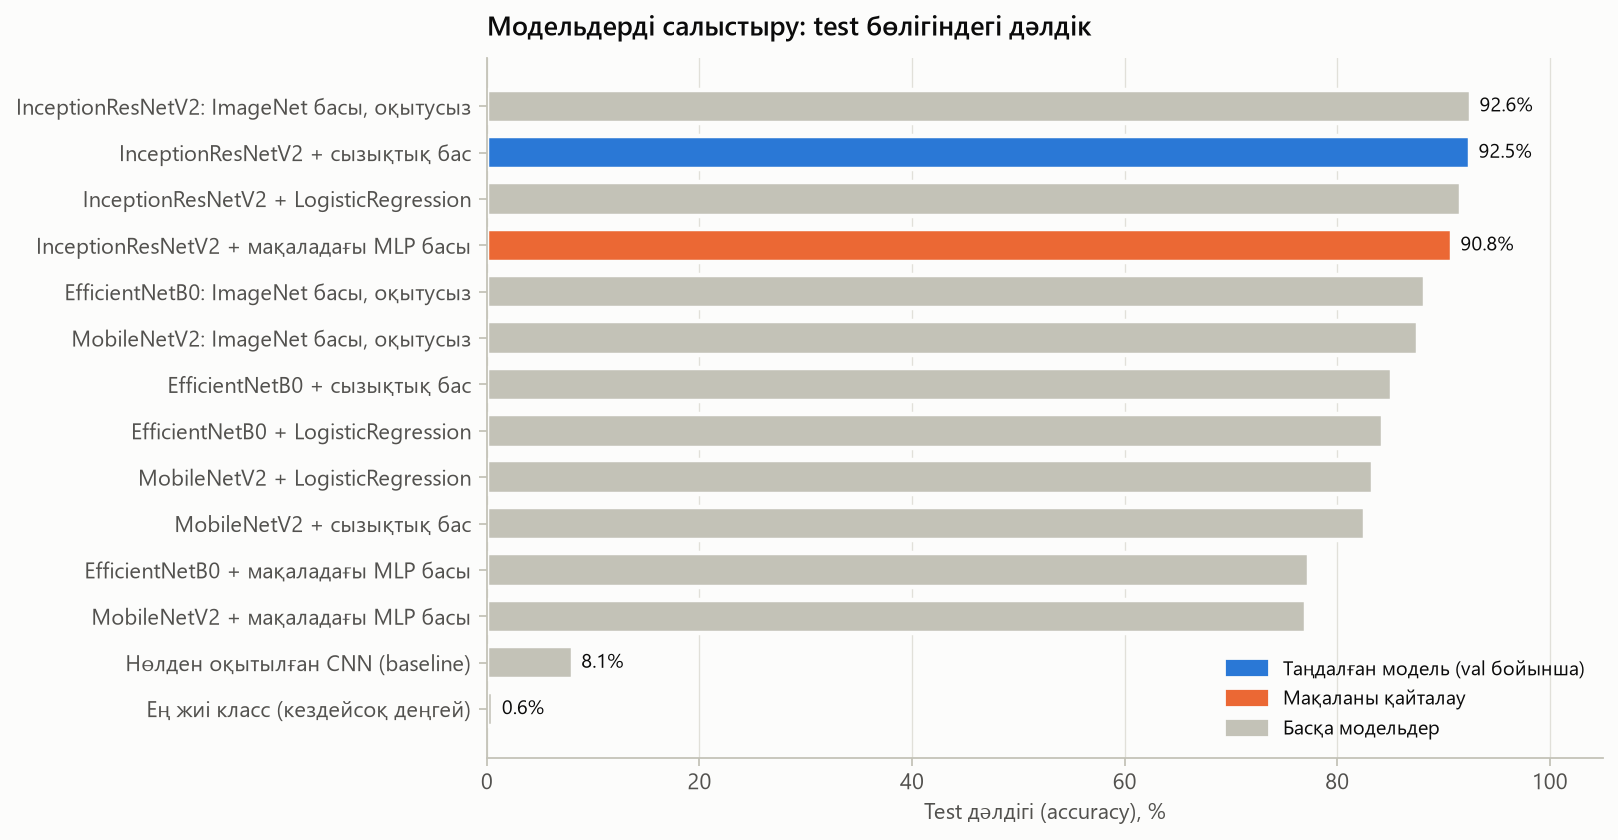

In [6]:
display(Image(filename=str(FIG_DIR / "model_comparison.png")))

**Негізгі бақылаулар**

1. **Transfer learning шешуші рөл атқарады.** Нөлден оқытылған CNN небәрі **8,1%** алды (кездейсоқ деңгей ≈ 0,8%).
   Ал сол деректерде мұздатылған InceptionResNetV2 белгілерінің үстіндегі қарапайым классификатор **92,5%** береді.
   10 мың суретпен 120 ұқсас тұқымды нөлден үйрену өте қиын. ImageNet-те үйренген белгілер (жүн текстурасы, құлақ пен тұмсық пішіні) бұл мәселені шешеді.
2. **Негізгі желі маңызды.** Үлкен желі дәлірек: MobileNetV2 → EfficientNetB0 → InceptionResNetV2, бірақ баяуырақ (төмендегі графикті қараңыз).
3. **Қарапайым бас мақаладағы MLP-ден жақсы.** InceptionResNetV2 үшін: сызықтық бас 92,5%, LogisticRegression 91,6%, мақаладағы MLP 90,8%.
   Белгілер онсыз да күшті болғандықтан, параметрі аз модель аз шамадан тыс үйренеді, ал оның ықтималдықтары шынайырақ (log loss пен ECE төмен).
4. **Оқытусыз ImageNet басы** (InceptionResNetV2: ImageNet басы, оқытусыз): **92,6%**. Бұл ImageNet-тің өзінде осы 120 тұқым бар екенін көрсетеді
   (Stanford Dogs ImageNet-тен құралған). Бұл маңызды **шектеу**: test суреттерінің бір бөлігін алдын ала үйретілген желі бұрын «көрген» болуы мүмкін,
   сондықтан нақты өмірдегі жаңа суреттерде дәлдік төменірек болуы ықтимал. Бұл модельдер салыстыру үшін ғана берілген: соңғы модельді біз оқытқан бастардың ішінен таңдадық.

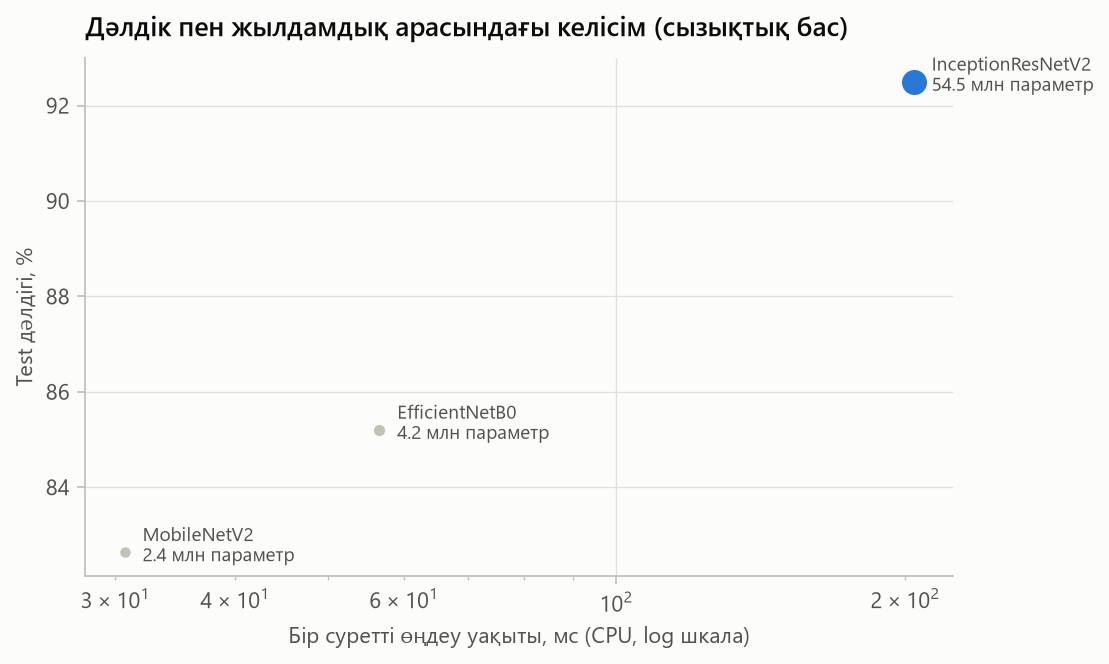

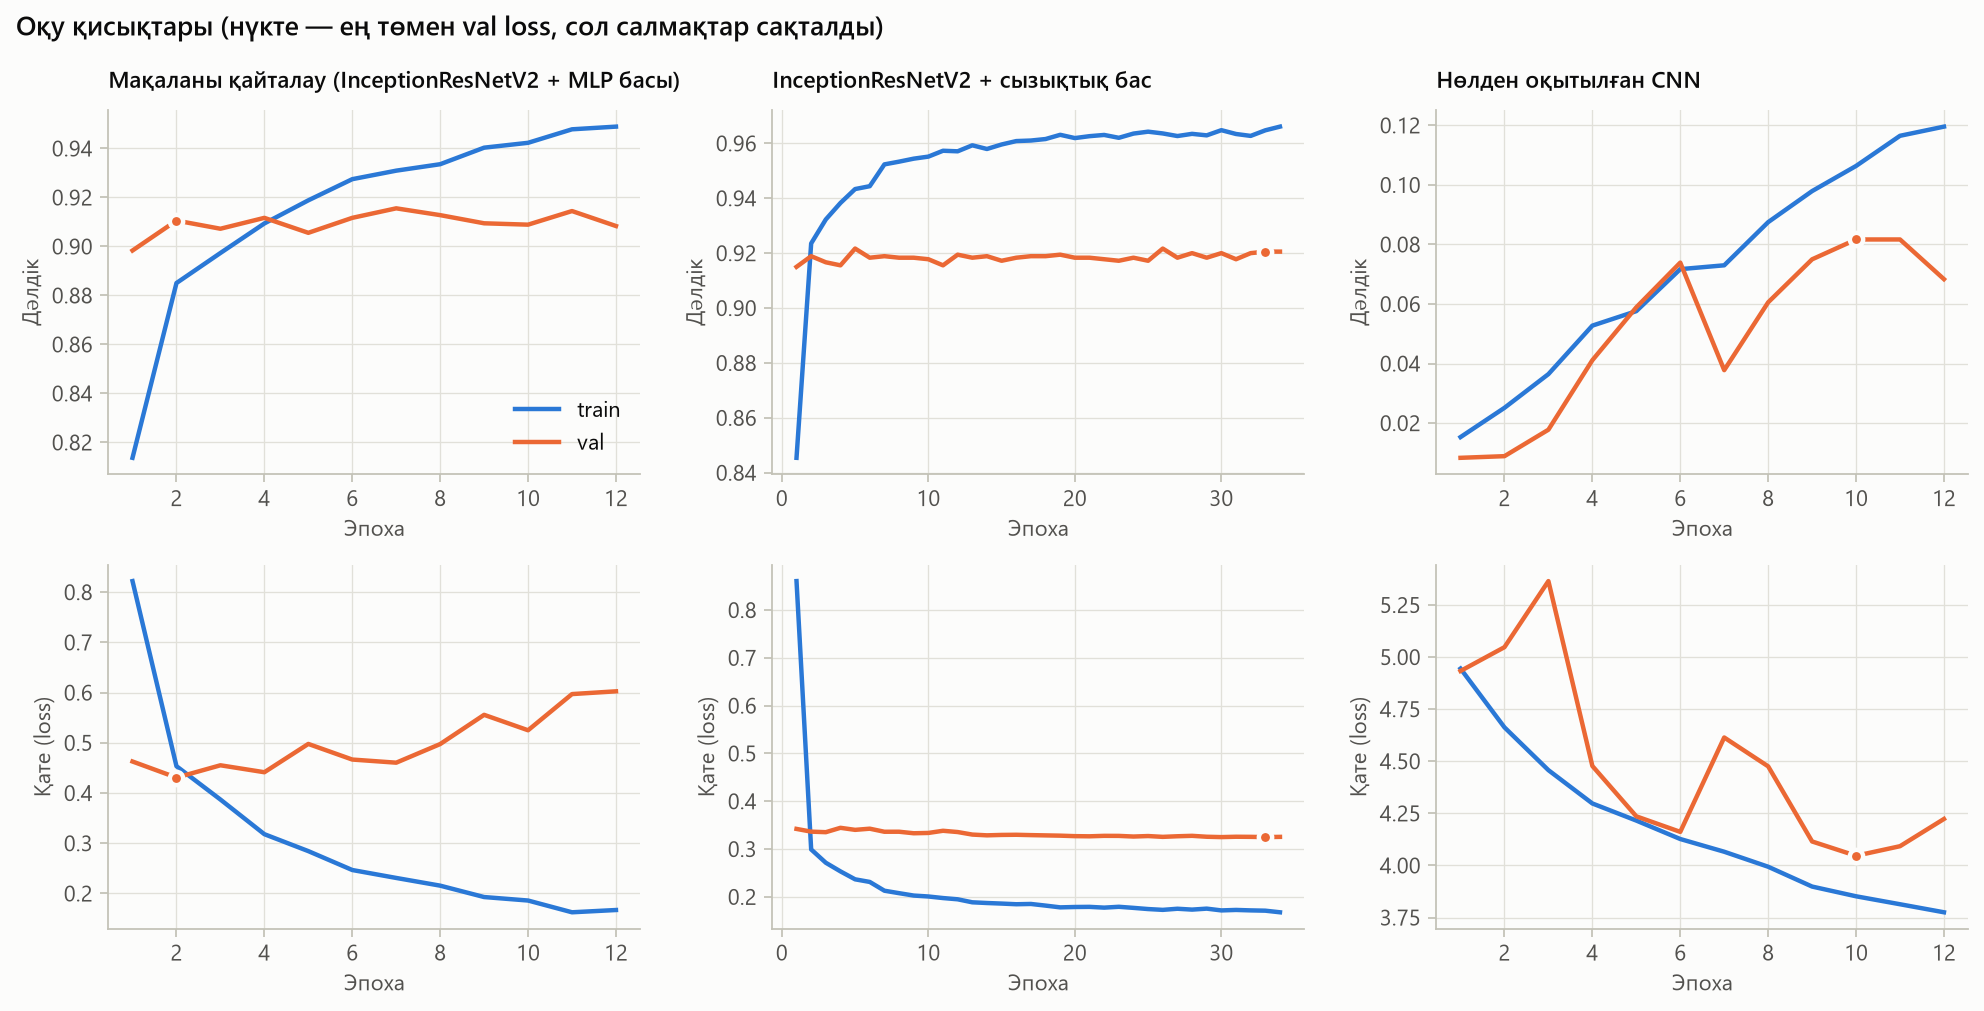

In [7]:
display(Image(filename=str(FIG_DIR / "accuracy_vs_latency.png")))
display(Image(filename=str(FIG_DIR / "training_curves.png")))

## 4. Соңғы модельді таңдау

Таңдау ережесі: **ең жоғары val дәлдігі** (тең болса — ең төмен val log loss), тек біз оқытқан transfer learning модельдері ішінен.

**Таңдалған модель:** InceptionResNetV2 + сызықтық бас (val дәлдігі 92,2%).

| Метрика (test, 8580 сурет) | Мәні |
|---|---|
| Accuracy | 92,5% |
| Top-5 accuracy | 99,4% |
| Macro precision / recall / F1 | 92,2% / 92,3% / 92,2% |
| Weighted F1 | 92,5% |
| Log loss | 0.249 |
| ECE (калибрлеу қатесі) | 0.012 |

**Неге тек accuracy емес?** Test теңестірілмеген (бір тұқымға 48–152 сурет). Сондықтан әр тұқымды тең ескеретін **macro F1** маңызды.
Ұқсас тұқымдар көп болғандықтан, **top-5** пайдаланушыға да пайдалы. **Log loss** пен **ECE** ықтималдықтардың сенімділігін көрсетеді: сайттағы «сенімсіз» ескертуі осыған сүйенеді.

In [8]:
final = load_json(METRICS_DIR / "final_model.json")
final

{'model_id': 'inception_resnet_v2__linear',
 'title': 'InceptionResNetV2 + сызықтық бас',
 'backbone': 'inception_resnet_v2',
 'head': 'linear',
 'tta': False,
 'input_size': 299,
 'test_metrics': {'accuracy': 0.9249,
  'top5_accuracy': 0.9943,
  'macro_precision': 0.9221,
  'macro_recall': 0.9229,
  'macro_f1': 0.9219,
  'weighted_f1': 0.9252,
  'balanced_accuracy': 0.9229,
  'log_loss': 0.2491,
  'ece': 0.0124},
 'val_accuracy': 0.9217,
 'params': 54521176,
 'latency_ms': 204.3,
 'low_confidence_threshold': 0.5,
 'accuracy_when_conf_ge_threshold': 0.937,
 'share_conf_ge_threshold': 0.9766,
 'accuracy_when_conf_lt_threshold': 0.4229,
 'confidence_thresholds': [{'threshold': 0.3,
   'share_above': 0.9972,
   'accuracy_above': 0.9268,
   'accuracy_below': 0.25},
  {'threshold': 0.4,
   'share_above': 0.9913,
   'accuracy_above': 0.9299,
   'accuracy_below': 0.36},
  {'threshold': 0.5,
   'share_above': 0.9766,
   'accuracy_above': 0.937,
   'accuracy_below': 0.4229},
  {'threshold': 0.6

## 5. Қателерді талдау

### 5.1. Қай тұқымдар нашар танылады және немен шатастырылады?

Ең нашар 10 тұқым (F1):


,breed,precision,recall,f1,support
97,Eskimo dog,0.413,0.520,0.460,50
80,Collie,0.756,0.642,0.694,53
99,Siberian husky,0.729,0.674,0.701,92
28,Staffordshire bullterrier,0.778,0.764,0.771,55
36,Yorkshire terrier,0.757,0.828,0.791,64
53,Lhasa,0.793,0.802,0.798,86
89,Appenzeller,0.746,0.863,0.800,51
29,American Staffordshire terrier,0.779,0.828,0.803,64
15,Walker hound,0.786,0.830,0.807,53
114,Miniature poodle,0.804,0.818,0.811,55


Ең жиі шатастырылатын жұптар:


,true,predicted,count,share_of_true_class
0,Siberian husky,Eskimo dog,28,0.304
1,Eskimo dog,Siberian husky,15,0.300
2,Scottish deerhound,Irish wolfhound,13,0.098
3,Lhasa,Shih-Tzu,12,0.140
4,Collie,Border collie,11,0.208
5,Staffordshire bullterrier,American Staffordshire terrier,10,0.182
6,Shih-Tzu,Lhasa,9,0.079
7,Irish wolfhound,Scottish deerhound,9,0.076
8,Silky terrier,Yorkshire terrier,9,0.108
9,English foxhound,Walker hound,8,0.140


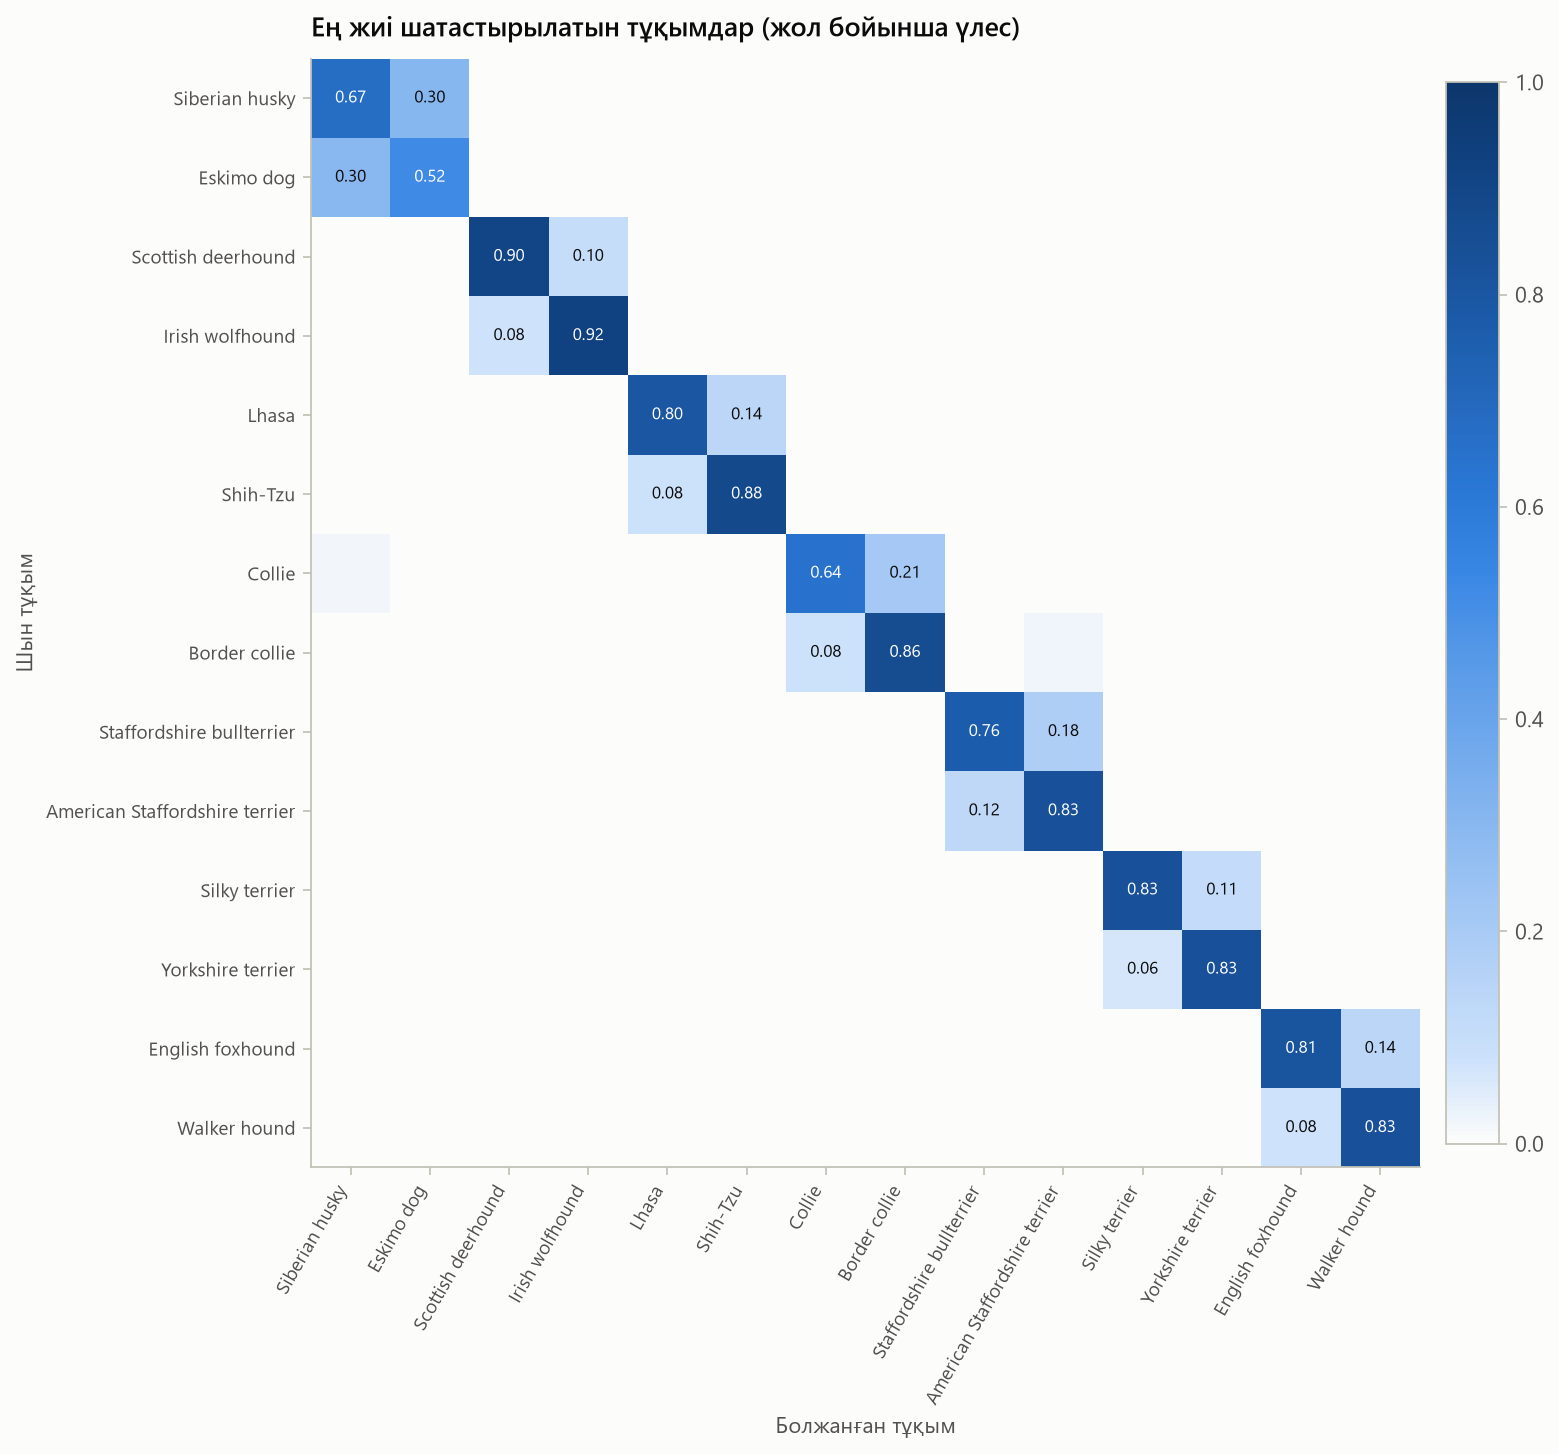

In [9]:
per_class = pd.read_csv(METRICS_DIR / "per_class.csv")
print("Ең нашар 10 тұқым (F1):")
display(per_class.sort_values("f1").head(10).round(3))
print("Ең жиі шатастырылатын жұптар:")
display(pd.read_csv(METRICS_DIR / "confused_pairs.csv").head(12))
display(Image(filename=str(FIG_DIR / "confusion_top.png")))

Шатастырылатын жұптардың көбі — **сырт келбеті өте ұқсас тұқымдар**: бір тұқымның түрлі өлшемдері (мысалы, toy/miniature poodle),
туыс тұқымдар (Siberian husky ↔ Eskimo dog ↔ malamute) немесе бір кезде бір тұқым болып саналған тұқымдар.
EDA-да бірдей суреттің екі түрлі тұқыммен белгіленгенін көрдік (мысалы, Walker hound ↔ English foxhound). Бұл тұқымдар арасындағы шекараның адамға да анық емес екенін көрсетеді.

### 5.2. Модель сенімді түрде қателескен суреттер

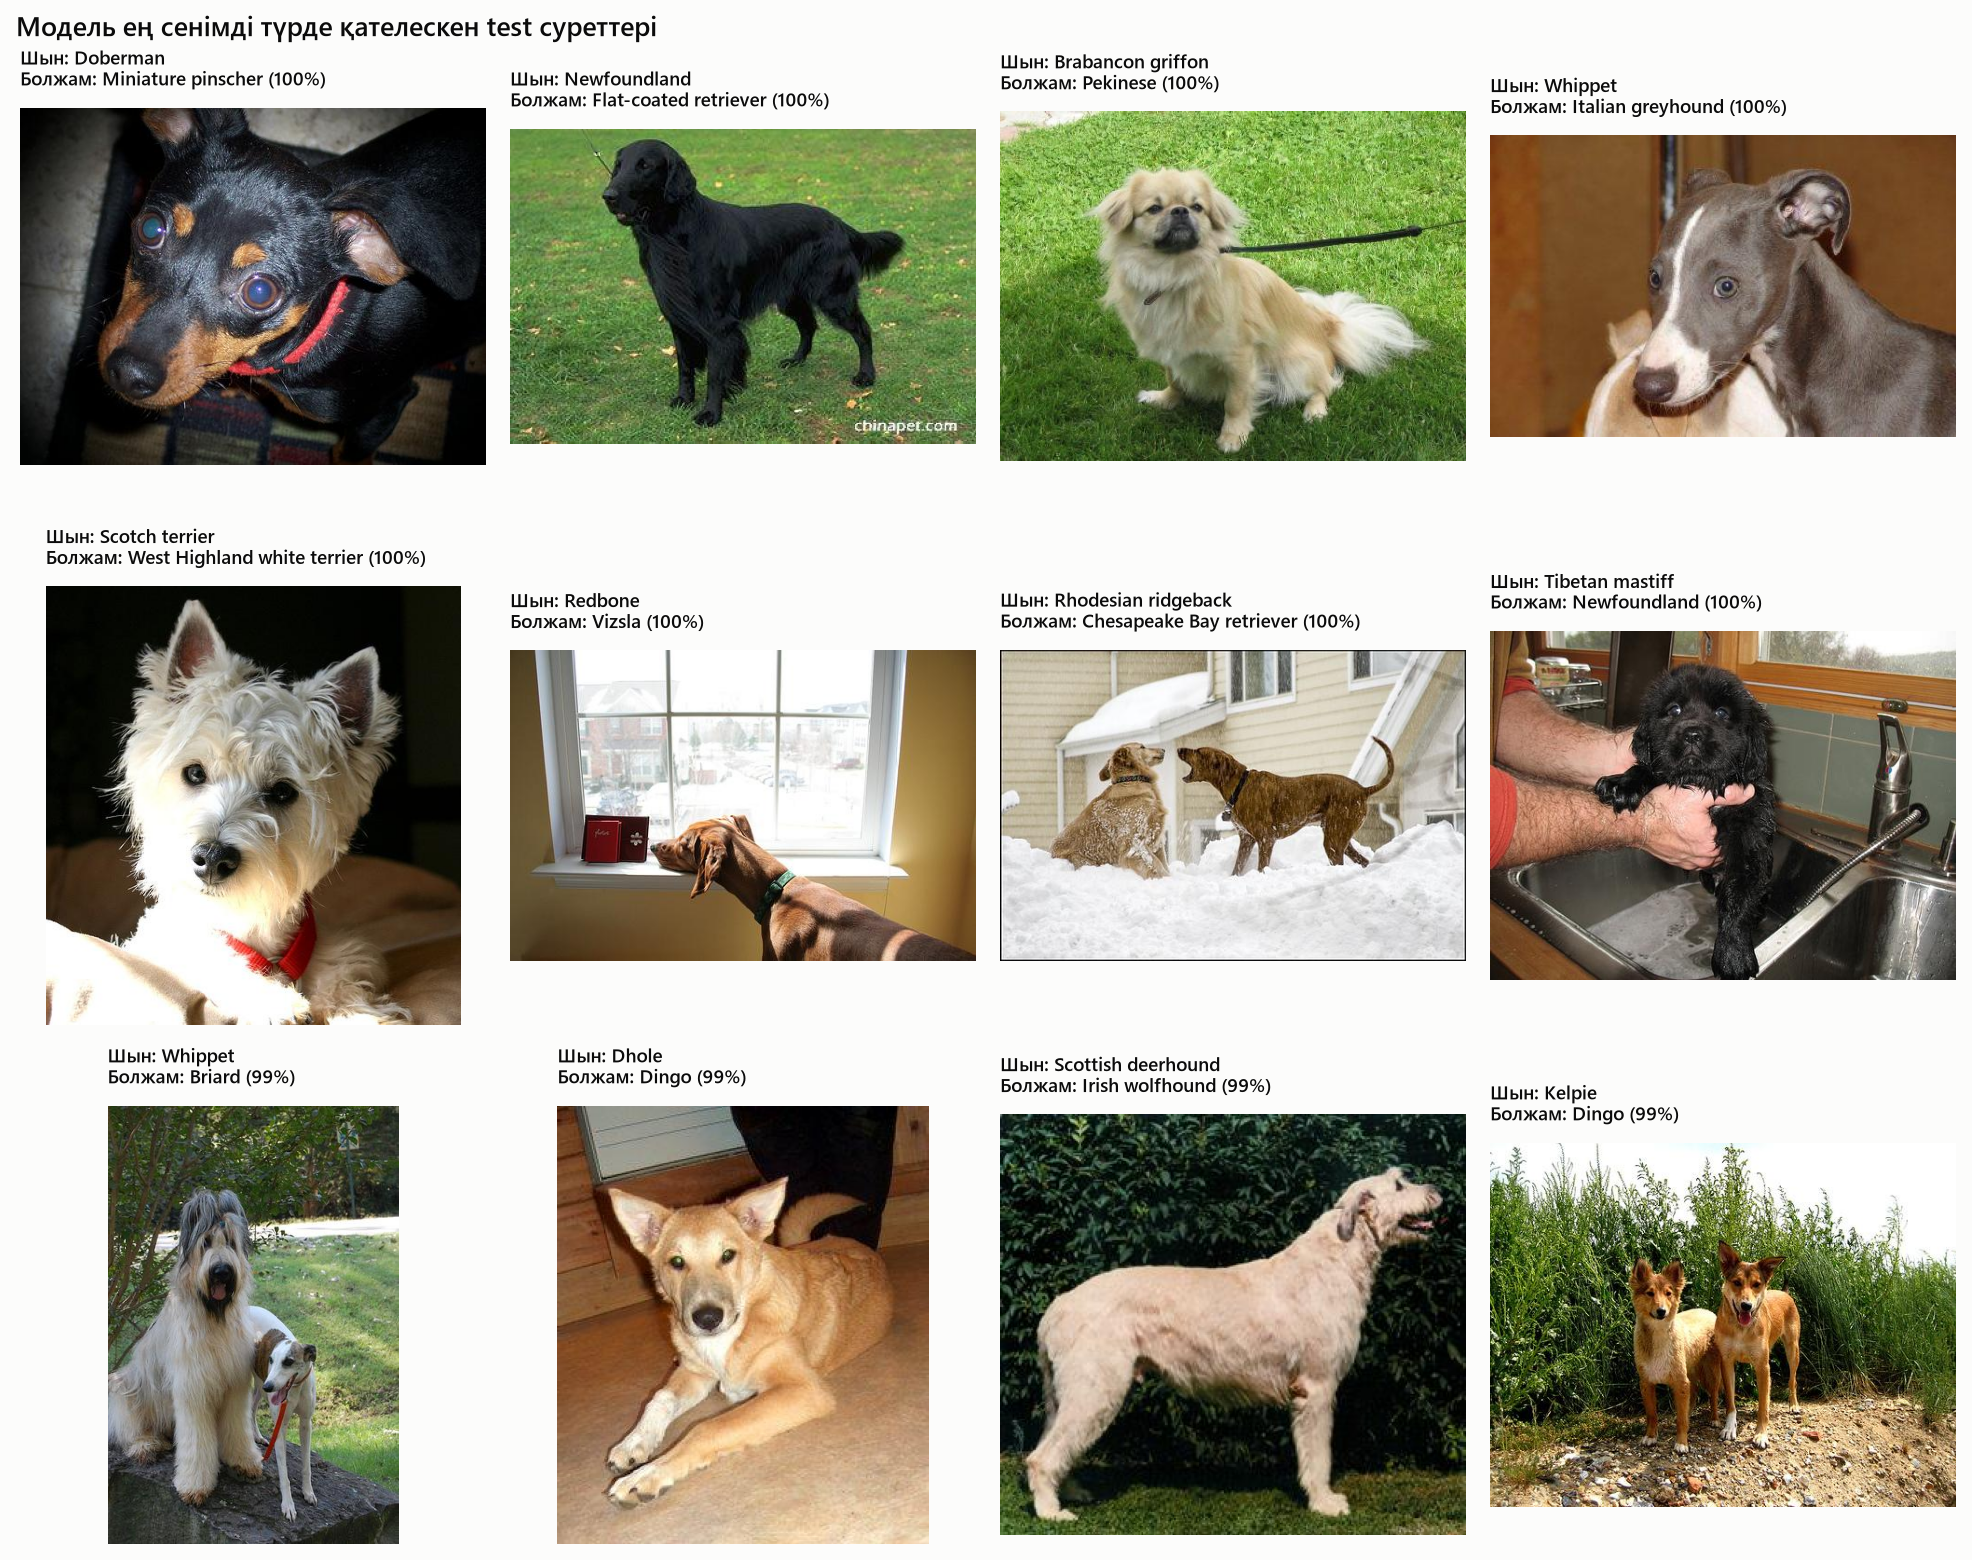

In [10]:
display(Image(filename=str(FIG_DIR / "misclassified_examples.png")))

### 5.3. Иттің кадрдағы өлшемі мен ит саны дәлдікке әсер ете ме?

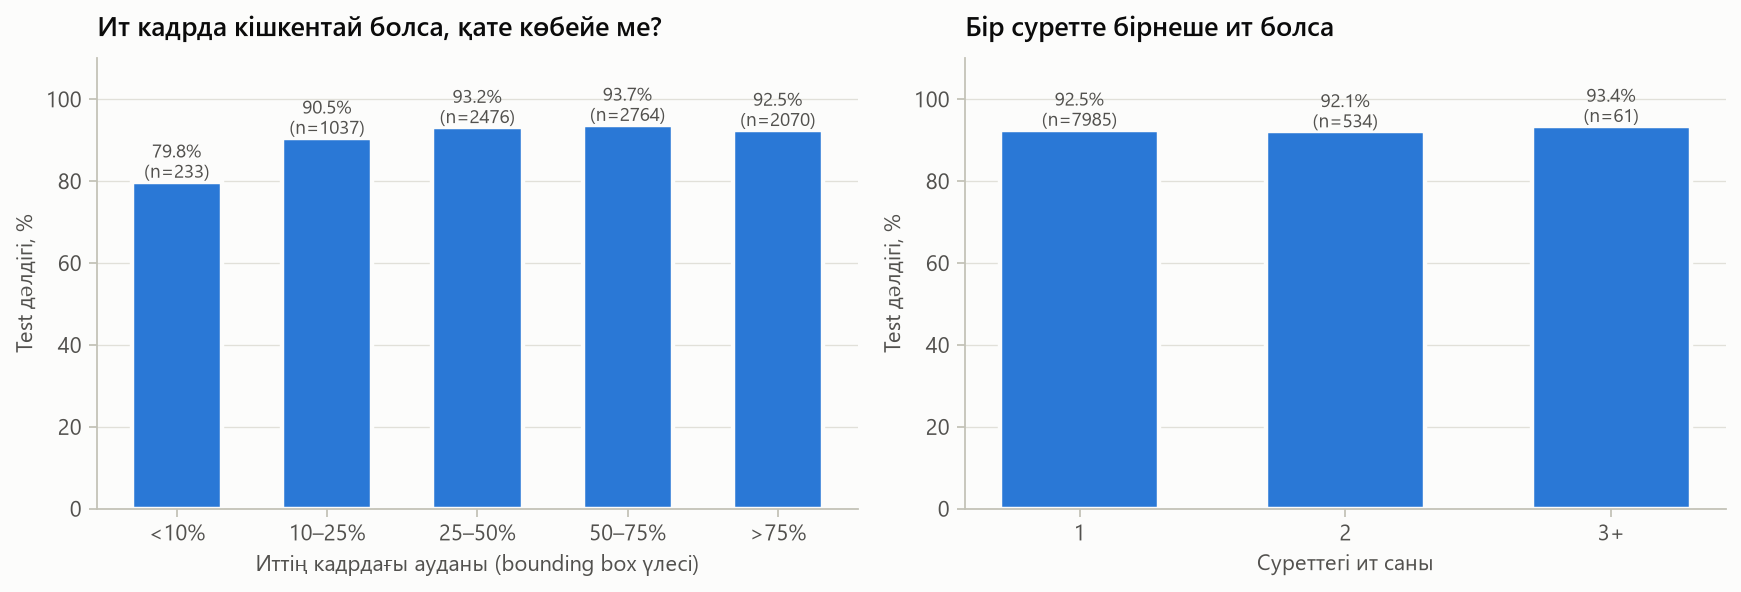

,accuracy,n
<10%,0.7983,233.0
10–25%,0.9055,1037.0
25–50%,0.9317,2476.0
50–75%,0.9370,2764.0
>75%,0.9246,2070.0


In [11]:
display(Image(filename=str(FIG_DIR / "error_vs_bbox.png")))
pd.DataFrame(load_json(METRICS_DIR / "summary.json")["error_vs_bbox"]["by_size"]).T

### 5.4. Сенімділік және калибрлеу

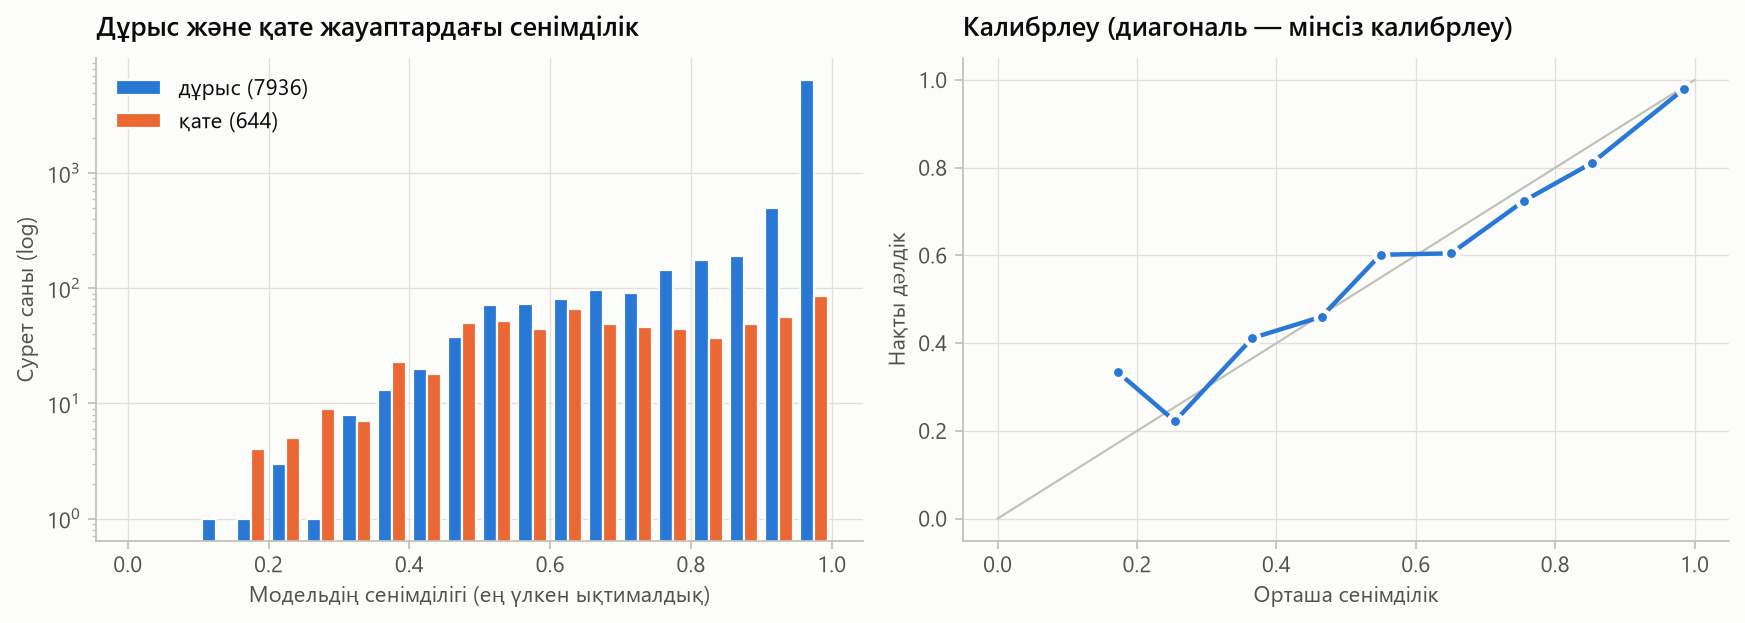

Сенімділігі ≥ 50% болжамдар үлесі: 97.7%, олардың дәлдігі: 93.7%


In [12]:
display(Image(filename=str(FIG_DIR / "confidence_calibration.png")))
print(f"Сенімділігі ≥ {final['low_confidence_threshold']:.0%} болжамдар үлесі: {final['share_conf_ge_threshold']:.1%},"
      f" олардың дәлдігі: {final['accuracy_when_conf_ge_threshold']:.1%}")

## 6. Шектеулер

- **Тек 120 тұқым.** Аралас тұқымдар мен басқа жануарлар үшін модель бәрібір бір тұқымды атайды. Сайтта бұл үшін екі тексеріс бар:
  ImageNet басы бойынша «суретте ит бар ма» және ең жоғары ықтималдық 50%-дан төмен болса «сенімсіз» ескертуі.
- **ImageNet-пен қиылысу.** Stanford Dogs суреттері ImageNet-тен алынған, сондықтан test нәтижесі нақты жаңа суреттерге қарағанда оптимистік болуы мүмкін.
- **Белгі қателері.** Деректерде бір сурет екі тұқыммен белгіленген жағдайлар бар. Олар train-нен алынды, бірақ test-те қалды.
- **Қиын суреттер.** Ит кадрда кішкентай болса, дәлдік айтарлықтай төмендейді (5.3-бөлім). Ит санының әсері әлсіз.
- **Жылдамдық.** Ең дәл InceptionResNetV2 CPU-да бір суретке ~0,3–0,4 с жұмсайды. Мобильді құрылғыға MobileNetV2 ыңғайлырақ, бірақ дәлдігі төмен.

## 7. Қорытынды

- Transfer learning нөлден оқытумен салыстырғанда дәлдікті бірнеше есе арттырды.
- Мақаланың нәтижесі (~90%) қайталанды. Қарапайым сызықтық бас мақаладағы MLP-ден жақсы нәтиже берді.
- Ең жақсы модель val бойынша таңдалып, сайтқа (FastAPI) енгізілді.
- **Болашақта:** GPU-да fine-tuning, заманауи архитектуралар (EfficientNetV2, ConvNeXt, ViT), итті алдымен детектормен қиып алу, ImageNet-ке кірмеген тәуелсіз суреттерде тексеру.